In [51]:
import pandas as pd
import numpy as np

data = {
    "Rumah": ["Rumah A", "Rumah B", "Rumah C", "Rumah D"],
    "Aktual": [500, 700, 900, 1100],
    "Prediksi": [480, 680, 850, 950],
}

df = pd.DataFrame(data)
df.head()

,Rumah,Aktual,Prediksi
0,Rumah A,500,480
1,Rumah B,700,680
2,Rumah C,900,850
3,Rumah D,1100,950


In [52]:
from sklearn.metrics import mean_absolute_error

# Mean Absolute Error (MAE)
mae = mean_absolute_error(df["Aktual"], df["Prediksi"])
print(f"Mean Absolute Error (MAE): {mae}")

Mean Absolute Error (MAE): 60.0


In [53]:
from sklearn.metrics import mean_squared_error

# Mean Squared Error (MSE)
mse = mean_squared_error(df["Aktual"], df["Prediksi"])
print(f"Mean Squared Error (MSE): {mse}")

Mean Squared Error (MSE): 6450.0


In [54]:
# Root Mean Squared Error (RMSE)

rmse = np.sqrt(mean_squared_error(df["Aktual"], df["Prediksi"]))
print(f"Root Mean Squared Error (RMSE): {rmse}")

Root Mean Squared Error (RMSE): 80.31189202104505


In [55]:
# Mean Absolute Percentage Error (MAPE)

df["Kesalahan"] = np.abs(df["Aktual"] - df["Prediksi"])
mape = np.mean(df["Kesalahan"] / df["Aktual"]) * 100
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

Mean Absolute Percentage Error (MAPE): 6.51%


In [56]:
import numpy as np
import pandas as pd

y_true = np.array([1, 1, 1, 1, 0, 1, 0, 0, 1, 1])
y_pred = np.array([1, 0, 1, 0, 0, 1, 1, 0, 1, 1])

[[2 1]
 [2 5]]
                Prediksi Negatif  Prediksi Positif
Aktual Negatif                 2                 2
Aktual Positif                 1                 5


Text(45.72222222222221, 0.5, 'Aktual')

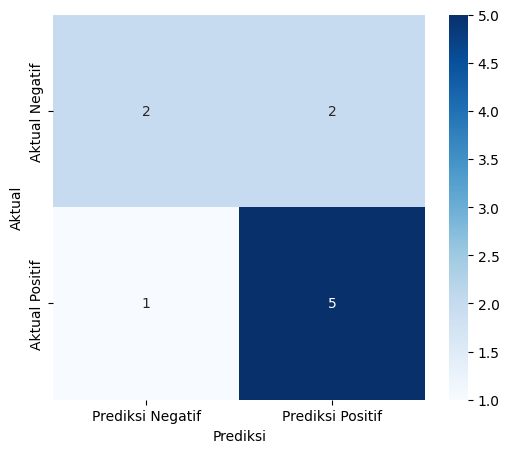

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

conf_matrix = confusion_matrix(y_true, y_pred)
print(conf_matrix)

cm = pd.DataFrame({
    "Prediksi Negatif" : [conf_matrix[0][0], conf_matrix[0][1]],
    "Prediksi Positif" : [conf_matrix[1][0], conf_matrix[1][1]]
}, index=["Aktual Negatif", "Aktual Positif"])

print(cm) 

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, cmap="Blues")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

In [58]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_true, y_pred)
print(f"Akurasi: {accuracy:.2f}")

Akurasi: 0.70


In [59]:
count_0 = np.sum(y_true == 0)
count_1 = np.sum(y_true == 1)

print(f"Jumlah kelas 0 (Negatif): {count_0}")
print(f"Jumlah kelas 1 (Positif): {count_1}")

Jumlah kelas 0 (Negatif): 3
Jumlah kelas 1 (Positif): 7


In [60]:
from sklearn.metrics import precision_score

precision = precision_score(y_true, y_pred)
print(f"Precision: {precision:.2f}")

Precision: 0.83


In [61]:
from sklearn.metrics import recall_score

recall = recall_score(y_true, y_pred)
print(f"Recall: {recall:.2f}")

Recall: 0.71


In [62]:
from sklearn.metrics import f1_score

f1 = f1_score(y_true, y_pred)
print(f"F1-Score: {f1:.3f}")

F1-Score: 0.769


In [63]:
from sklearn.metrics import roc_auc_score

score = roc_auc_score(y_true, y_pred)
print(f"ROC AUC Score: {score:.2f}")

ROC AUC Score: 0.69


In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, 
    classification_report, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score
)

df = pd.read_csv('data_metrik.csv')

print("=== 5 Data Pertama ===")
print(df)

=== 5 Data Pertama ===
   email_id  actual_label  predicted_label
0       E01             1                1
1       E02             0                0
2       E03             1                0
3       E04             0                0
4       E05             1                1
5       E06             0                1
6       E07             0                0
7       E08             1                1
8       E09             0                0
9       E10             1                1
10      E11             0                0
11      E12             1                0
12      E13             0                0
13      E14             1                1
14      E15             0                0
15      E16             0                0
16      E17             1                1
17      E18             0                1
18      E19             1                1
19      E20             0                0


In [65]:
# 1 = true, 0 = false

dist_tp = df.loc[(df['actual_label'] == 1) & (df['predicted_label'] == 1)]
dist_tn = df.loc[(df['actual_label'] == 0) & (df['predicted_label'] == 0)]
dist_fp = df.loc[(df['actual_label'] == 0) & (df['predicted_label'] == 1)]
dist_fn = df.loc[(df['actual_label'] == 1) & (df['predicted_label'] == 0)]


=== Hasil Evaluasi Metrik ===


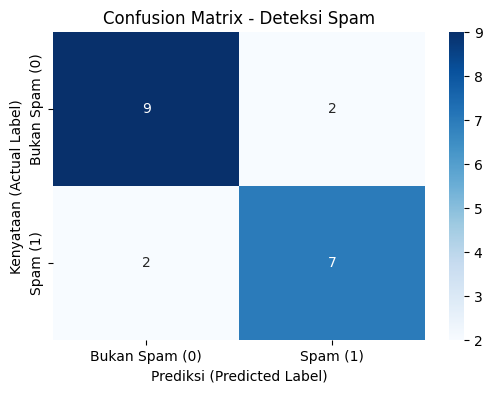

Accuracy  : 0.80 (80%)
Precision : 0.78 (78%)
Recall    : 0.78 (78%)
F1-Score  : 0.78

=== Classification Report ===
                precision    recall  f1-score   support

Bukan Spam (0)       0.82      0.82      0.82        11
      Spam (1)       0.78      0.78      0.78         9

      accuracy                           0.80        20
     macro avg       0.80      0.80      0.80        20
  weighted avg       0.80      0.80      0.80        20



In [66]:
# ==========================================
# 3. EVALUASI METRIK KLASIFIKASI
# ==========================================
print("\n=== Hasil Evaluasi Metrik ===")

# Confusion Matrix
cm = confusion_matrix(df['actual_label'], df['predicted_label'])

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Bukan Spam (0)', 'Spam (1)'], 
            yticklabels=['Bukan Spam (0)', 'Spam (1)'])
plt.xlabel('Prediksi (Predicted Label)')
plt.ylabel('Kenyataan (Actual Label)')
plt.title('Confusion Matrix - Deteksi Spam')
plt.show()

# Menghitung Metrik Utama
acc = accuracy_score(df['actual_label'], df['predicted_label'])
prec = precision_score(df['actual_label'], df['predicted_label'])
rec = recall_score(df['actual_label'], df['predicted_label'])
f1 = f1_score(df['actual_label'], df['predicted_label'])

print(f"Accuracy  : {acc:.2f} ({(acc*100):.0f}%)")
print(f"Precision : {prec:.2f} ({(prec*100):.0f}%)")
print(f"Recall    : {rec:.2f} ({(rec*100):.0f}%)")
print(f"F1-Score  : {f1:.2f}\n")

print("=== Classification Report ===")
print(classification_report(df['actual_label'], df['predicted_label'], 
                            target_names=['Bukan Spam (0)', 'Spam (1)']))